#Breast Cancer Classification
Mariana Hernandez


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn import preprocessing
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler

In [ ]:
from google.colab import files
dataset = files.upload()
brst_cancer_df = pd.read_csv('breast-cancer.csv')

Saving breast-cancer.csv to breast-cancer (12).csv


# Dataset Exploration

In [ ]:
#created a copy in case file values change unwantedly
brst_cancer_c_df = brst_cancer_df.copy()
print("Number of samples: " + str(len(brst_cancer_c_df)))
print("Number of features: " + str(len(brst_cancer_c_df.columns)))
brst_cancer_c_df


Number of samples: 569
Number of features: 32


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [ ]:
#check if there are any missing values
mvars=brst_cancer_df.isna().sum()
print(mvars[mvars>0])

Series([], dtype: int64)




*   569 samples (# of rows)
*   30 raw features -> 32 columns - 2 columns (id and diagnosis)
* 1 Categorical variable (diagnosis)
* No missing values



In [ ]:
#checking if our dataset is balanced
num_malignant = len(brst_cancer_c_df[brst_cancer_c_df['diagnosis'] == 'M'])
num_benign = len(brst_cancer_c_df[brst_cancer_c_df['diagnosis'] == 'B'])

print("Malignant samples:", num_malignant)
print("Benign samples:", num_benign)

Malignant samples: 212
Benign samples: 357


These results show that we have more benign samples than malignant making this a skewed dataset. This means that we have to make sure that the data split is stratified to get an even amount of malignant and benign samples. Additonally accuracy will not be reliable metric for this model since it will show better performance for benign samples rather than malignant

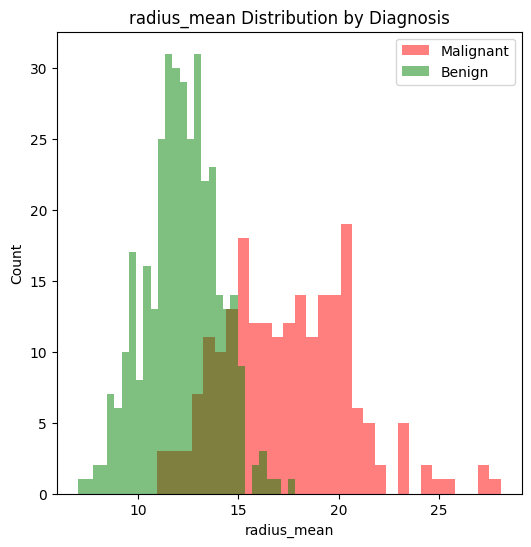

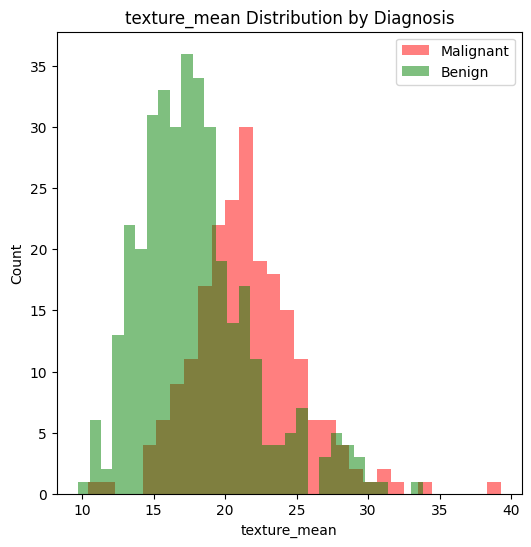

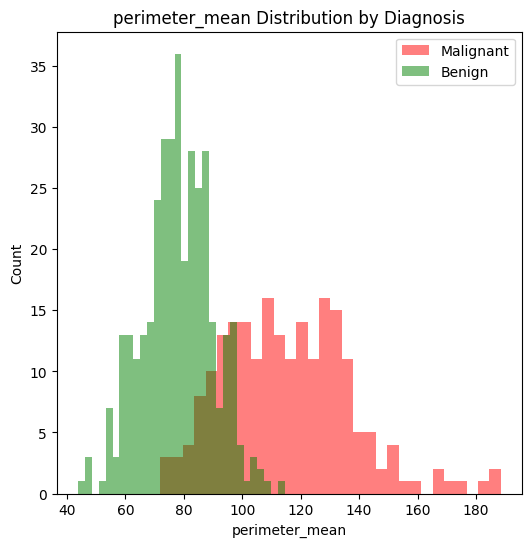

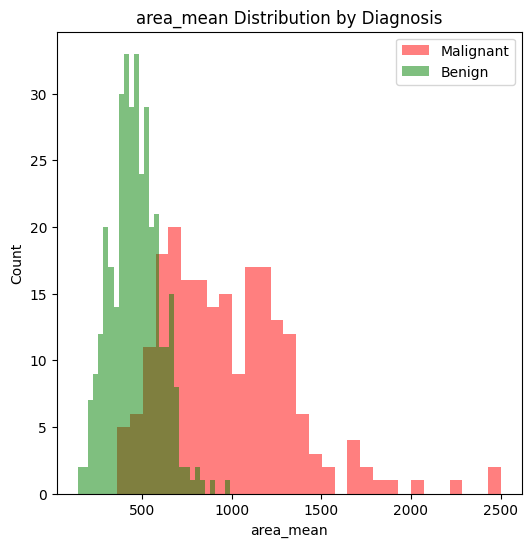

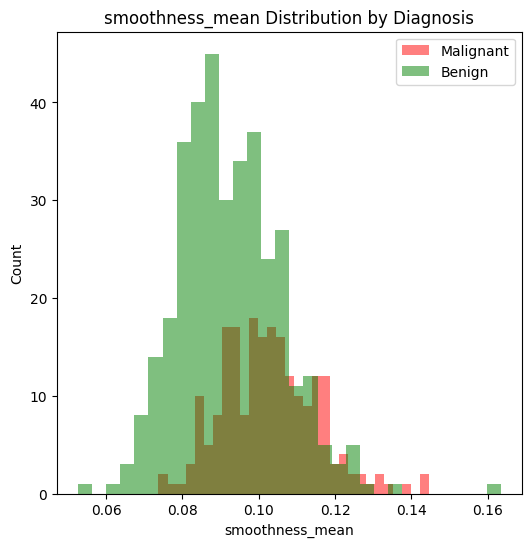

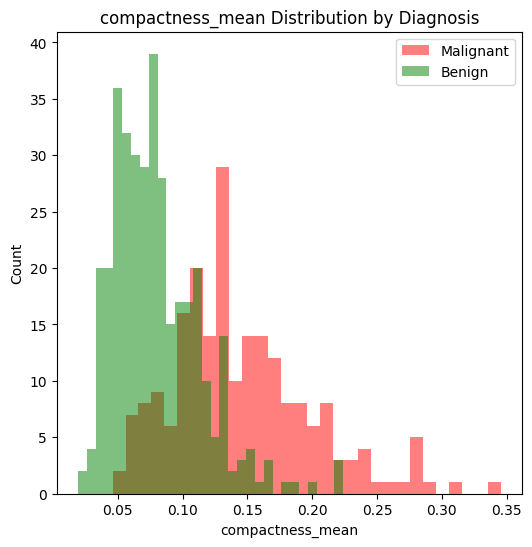

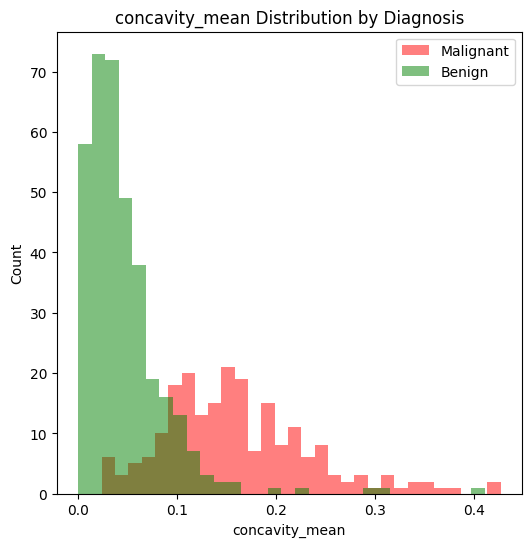

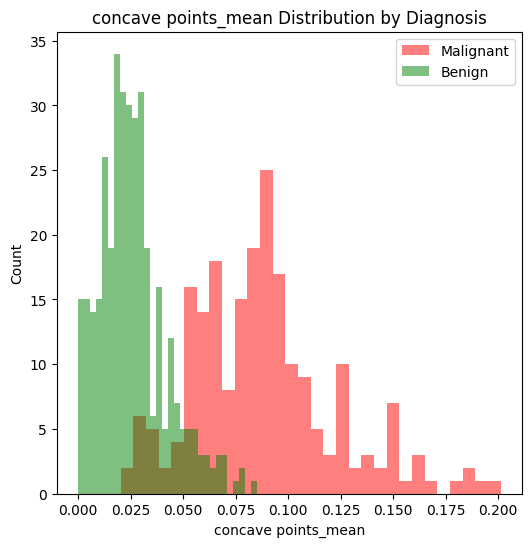

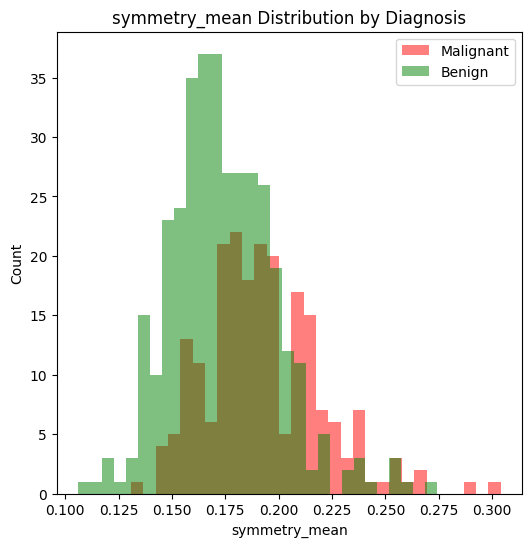

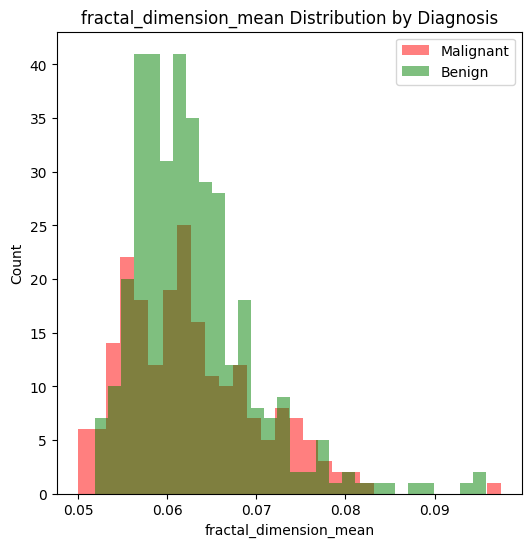

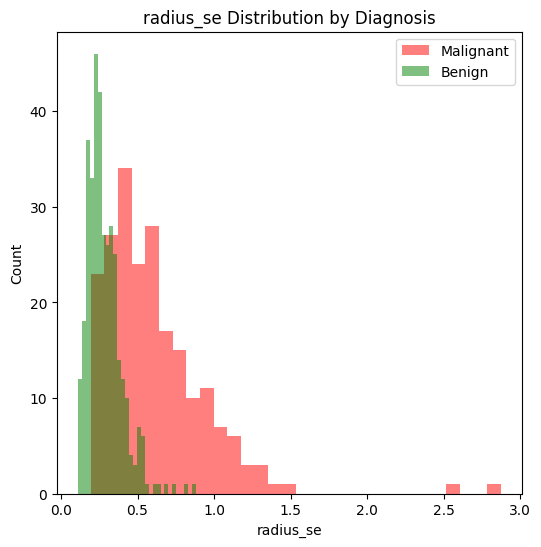

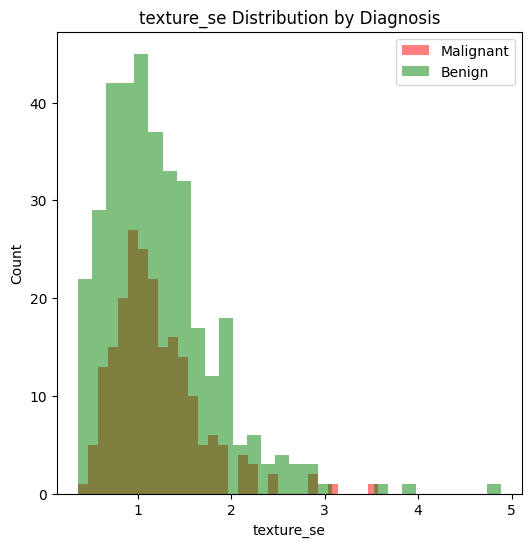

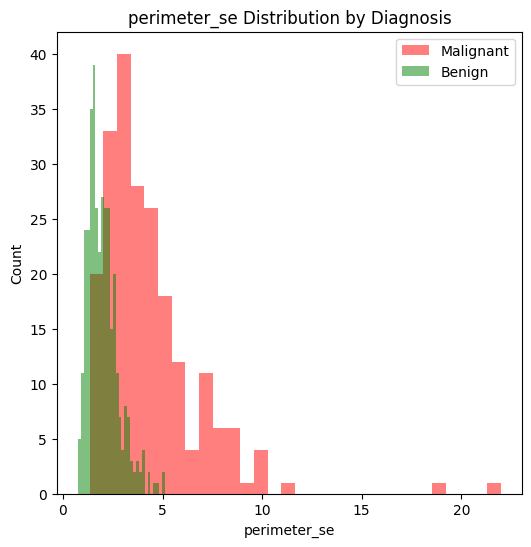

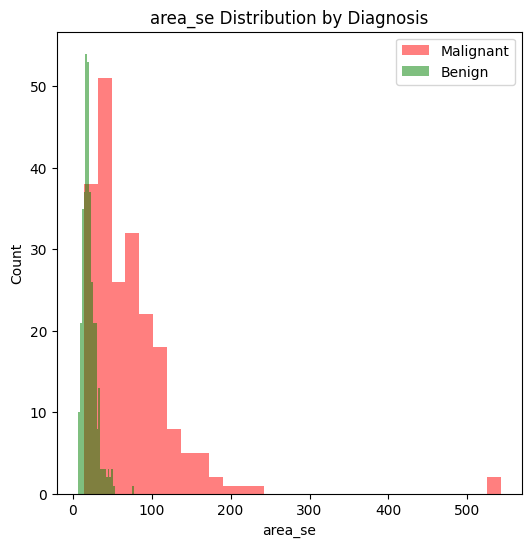

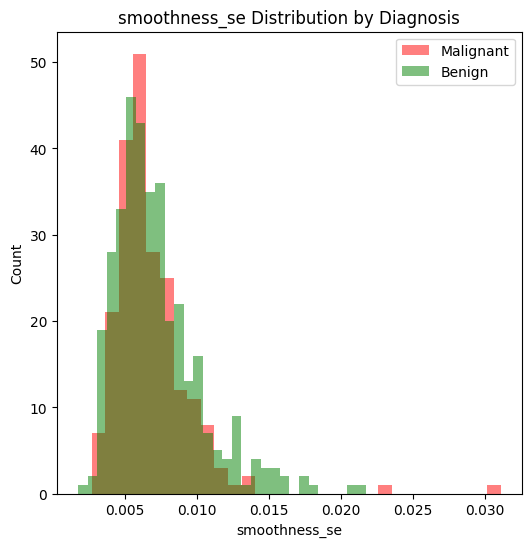

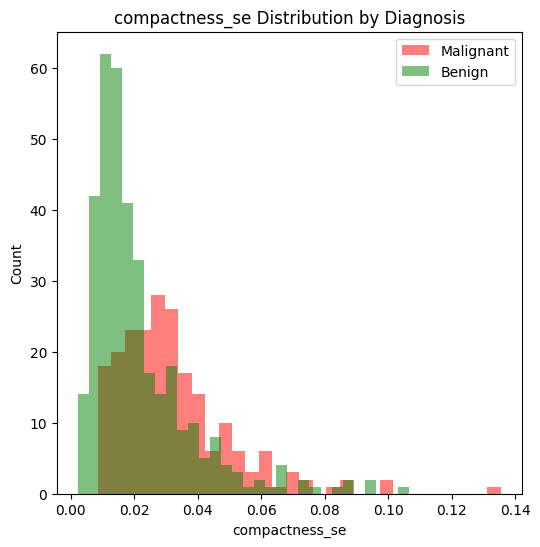

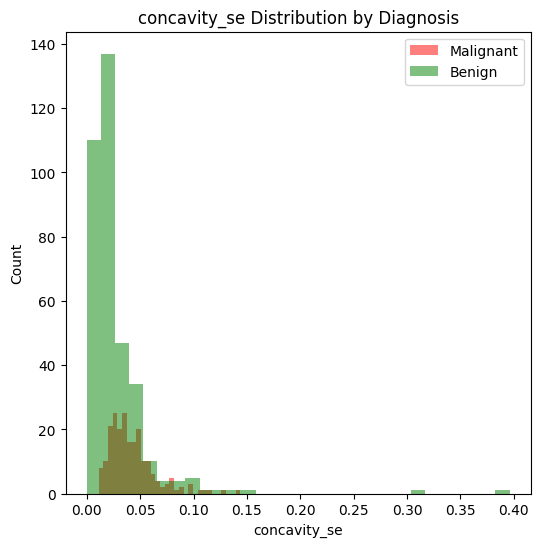

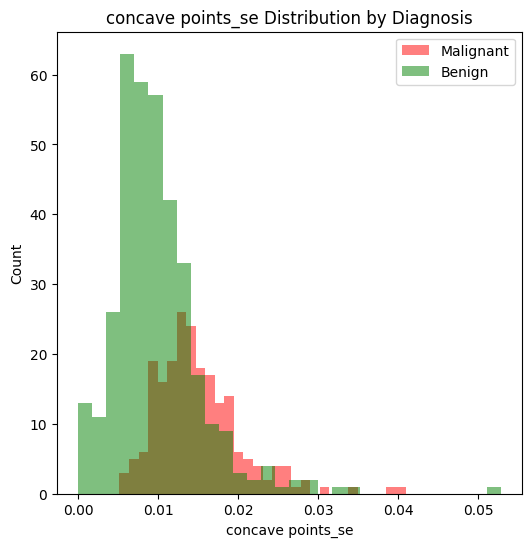

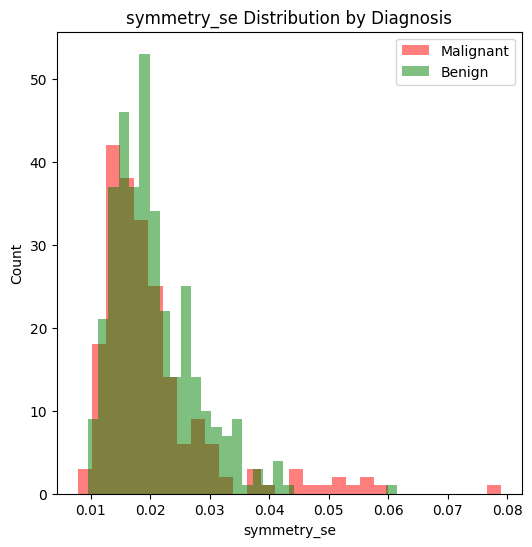

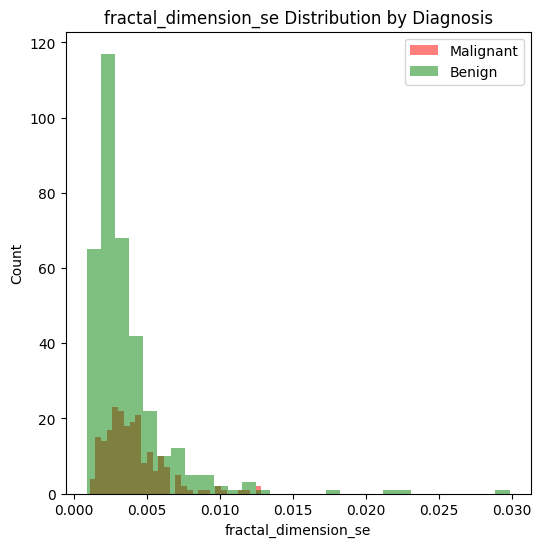

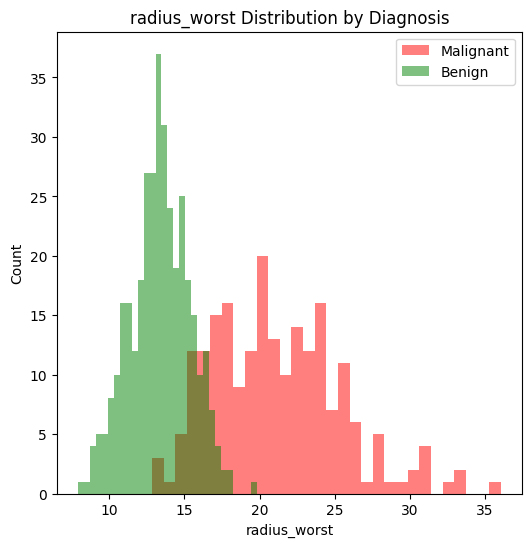

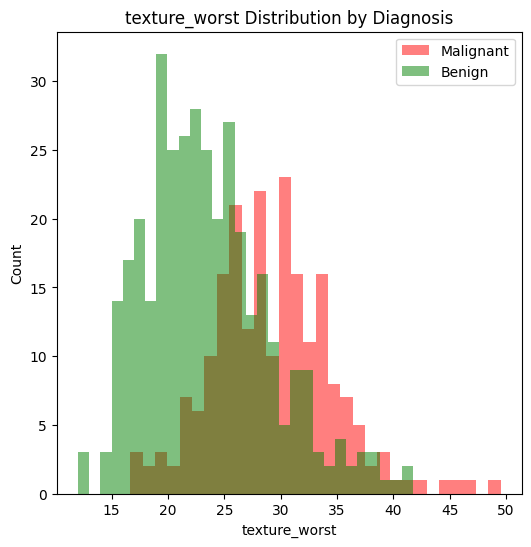

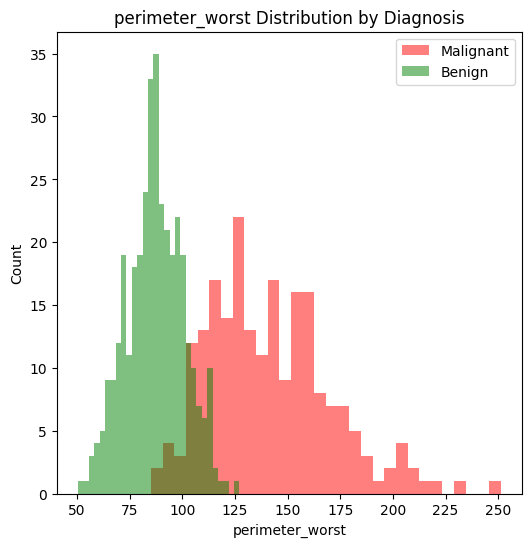

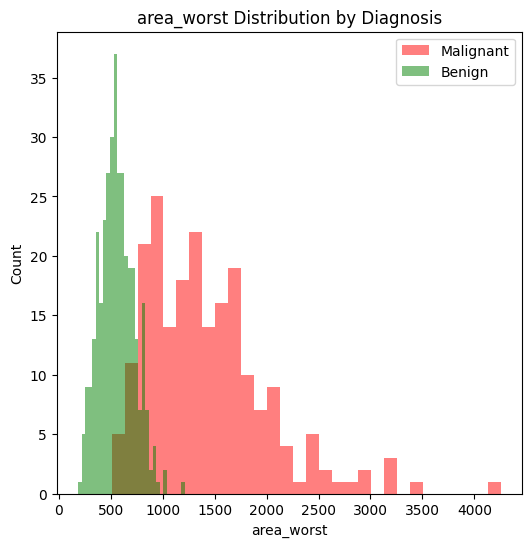

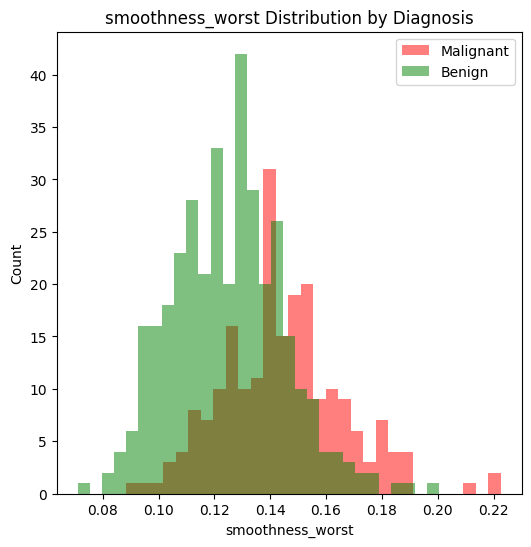

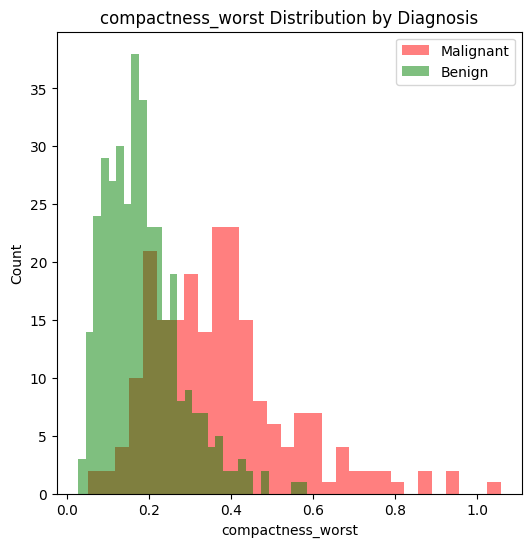

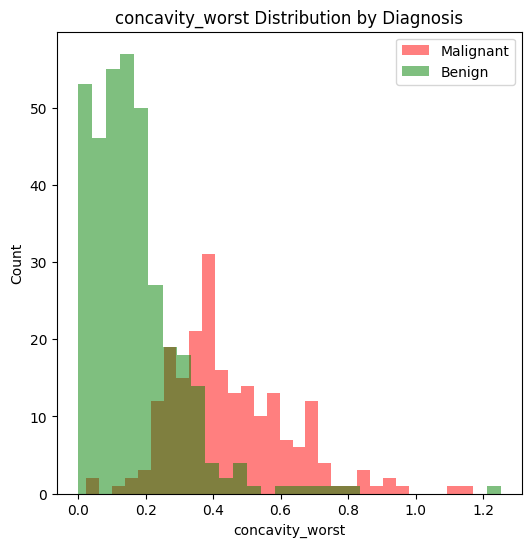

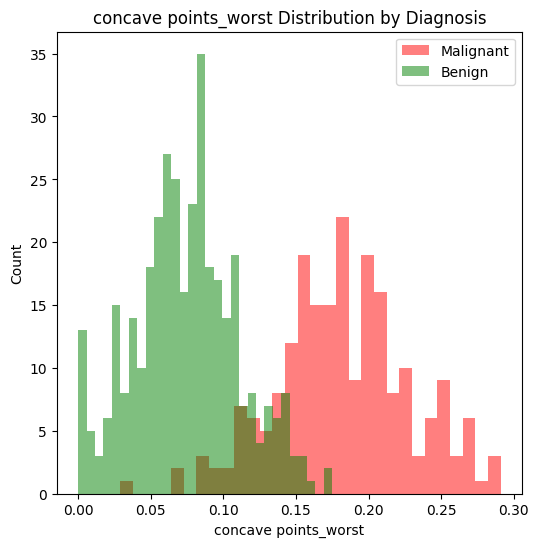

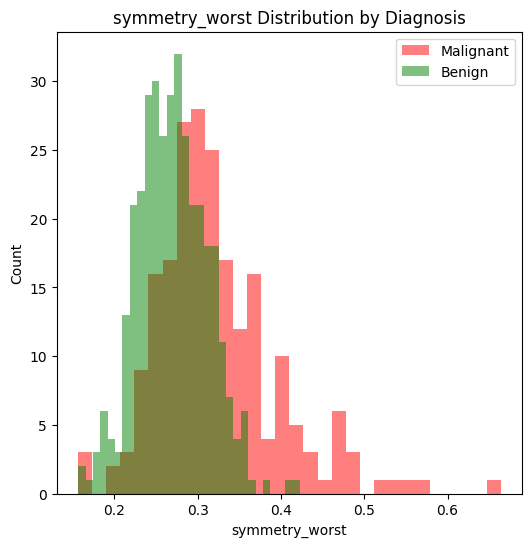

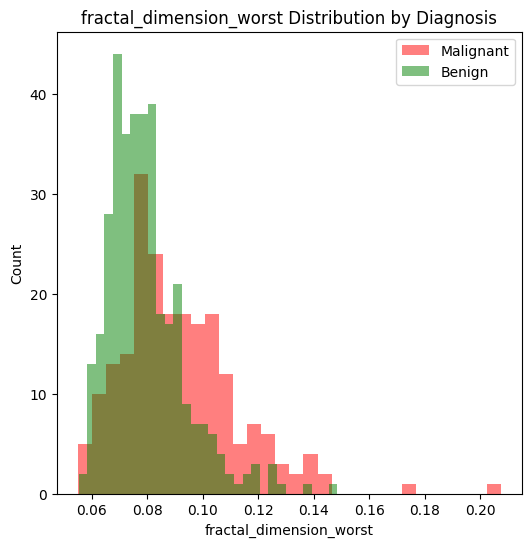

In [ ]:
features = brst_cancer_c_df.drop(['id', 'diagnosis'], axis=1).columns

malignant = brst_cancer_c_df[brst_cancer_c_df['diagnosis'] == 'M']
benign = brst_cancer_c_df[brst_cancer_c_df['diagnosis'] == 'B']

for feature in features:
    plt.figure(figsize=(6,6))
    plt.hist(malignant[feature], bins=30, alpha=0.5, label='Malignant', color='red')
    plt.hist(benign[feature], bins=30, alpha=0.5, label='Benign', color='green')
    plt.title(f'{feature} Distribution by Diagnosis')
    plt.xlabel(feature)
    plt.ylabel('Count')
    plt.legend()
    plt.show()

The histograms show that our features have a wide range of means and variance. Most importantly it also shows we have a large disparity in feature scales, such as compactness_se having values in the thousanths and area_wrost having data values in the thousands. This means that we need to standardize our data before training the the model. If we do not, certain features like area_worst will have a greater impact on the classification. Standardizing will also help with our K-NN model and kernerl for SVM since rbf relies on distance betweeen the data samples.

#Pre-Processing & Feauture Extraction

In [ ]:
#change diagnosis from M/B to 1/0
brst_cancer_c_df['diagnosis'] = brst_cancer_c_df['diagnosis'].map({'M': 1, 'B': 0})
brst_cancer_c_df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,1,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,1,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,1,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,1,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


Diagnosis was encoded to 0/1. This is necessary for K-NN and SVM since they depend on numerical class values to optimize and make their decison boundary.

###Not Used

In [ ]:
corr_matrix= brst_cancer_c_df.drop(['id','diagnosis'], axis=1).corr()
corr_matrix.style.background_gradient(cmap='coolwarm')

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
radius_mean,1.000000,0.323782,0.997855,0.987357,0.170581,0.506124,0.676764,0.822529,0.147741,-0.311631,0.679090,-0.097317,0.674172,0.735864,-0.222600,0.206000,0.194204,0.376169,-0.104321,-0.042641,0.969539,0.297008,0.965137,0.941082,0.119616,0.413463,0.526911,0.744214,0.163953,0.007066
texture_mean,0.323782,1.000000,0.329533,0.321086,-0.023389,0.236702,0.302418,0.293464,0.071401,-0.076437,0.275869,0.386358,0.281673,0.259845,0.006614,0.191975,0.143293,0.163851,0.009127,0.054458,0.352573,0.912045,0.358040,0.343546,0.077503,0.277830,0.301025,0.295316,0.105008,0.119205
perimeter_mean,0.997855,0.329533,1.000000,0.986507,0.207278,0.556936,0.716136,0.850977,0.183027,-0.261477,0.691765,-0.086761,0.693135,0.744983,-0.202694,0.250744,0.228082,0.407217,-0.081629,-0.005523,0.969476,0.303038,0.970387,0.941550,0.150549,0.455774,0.563879,0.771241,0.189115,0.051019
area_mean,0.987357,0.321086,0.986507,1.000000,0.177028,0.498502,0.685983,0.823269,0.151293,-0.283110,0.732562,-0.066280,0.726628,0.800086,-0.166777,0.212583,0.207660,0.372320,-0.072497,-0.019887,0.962746,0.287489,0.959120,0.959213,0.123523,0.390410,0.512606,0.722017,0.143570,0.003738
smoothness_mean,0.170581,-0.023389,0.207278,0.177028,1.000000,0.659123,0.521984,0.553695,0.557775,0.584792,0.301467,0.068406,0.296092,0.246552,0.332375,0.318943,0.248396,0.380676,0.200774,0.283607,0.213120,0.036072,0.238853,0.206718,0.805324,0.472468,0.434926,0.503053,0.394309,0.499316
compactness_mean,0.506124,0.236702,0.556936,0.498502,0.659123,1.000000,0.883121,0.831135,0.602641,0.565369,0.497473,0.046205,0.548905,0.455653,0.135299,0.738722,0.570517,0.642262,0.229977,0.507318,0.535315,0.248133,0.590210,0.509604,0.565541,0.865809,0.816275,0.815573,0.510223,0.687382
concavity_mean,0.676764,0.302418,0.716136,0.685983,0.521984,0.883121,1.000000,0.921391,0.500667,0.336783,0.631925,0.076218,0.660391,0.617427,0.098564,0.670279,0.691270,0.683260,0.178009,0.449301,0.688236,0.299879,0.729565,0.675987,0.448822,0.754968,0.884103,0.861323,0.409464,0.514930
concave points_mean,0.822529,0.293464,0.850977,0.823269,0.553695,0.831135,0.921391,1.000000,0.462497,0.166917,0.698050,0.021480,0.710650,0.690299,0.027653,0.490424,0.439167,0.615634,0.095351,0.257584,0.830318,0.292752,0.855923,0.809630,0.452753,0.667454,0.752399,0.910155,0.375744,0.368661
symmetry_mean,0.147741,0.071401,0.183027,0.151293,0.557775,0.602641,0.500667,0.462497,1.000000,0.479921,0.303379,0.128053,0.313893,0.223970,0.187321,0.421659,0.342627,0.393298,0.449137,0.331786,0.185728,0.090651,0.219169,0.177193,0.426675,0.473200,0.433721,0.430297,0.699826,0.438413
fractal_dimension_mean,-0.311631,-0.076437,-0.261477,-0.283110,0.584792,0.565369,0.336783,0.166917,0.479921,1.000000,0.000111,0.164174,0.039830,-0.090170,0.401964,0.559837,0.446630,0.341198,0.345007,0.688132,-0.253691,-0.051269,-0.205151,-0.231854,0.504942,0.458798,0.346234,0.175325,0.334019,0.767297


For feature extraction I decided to make a correlation table to be able to visualize the relationships among features. We want to remove features that are highly correlated to eachother or highly uncorrelated since they might be redudant to our model prediction.

In [ ]:
#feature extraction based on correlation table
col_corr = set()
for i in range(len(corr_matrix.columns)):
 for j in range(i):
      if abs(corr_matrix.iloc[i,j] > 0.9):
        colname = corr_matrix.columns[i]
        col_corr.add(colname)
print("Feautures removed:", len( set(col_corr)))
print(col_corr)

brst_cancer_reduced_df = brst_cancer_c_df.drop(col_corr, axis=1)
brst_cancer_reduced_df

Feautures removed: 10
{'perimeter_mean', 'radius_worst', 'area_mean', 'texture_worst', 'perimeter_worst', 'area_worst', 'concave points_mean', 'perimeter_se', 'area_se', 'concave points_worst'}


,id,diagnosis,radius_mean,texture_mean,smoothness_mean,compactness_mean,concavity_mean,symmetry_mean,fractal_dimension_mean,radius_se,...,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se,smoothness_worst,compactness_worst,concavity_worst,symmetry_worst,fractal_dimension_worst
0,842302,1,17.99,10.38,0.11840,0.27760,0.30010,0.2419,0.07871,1.0950,...,0.04904,0.05373,0.01587,0.03003,0.006193,0.16220,0.66560,0.7119,0.4601,0.11890
1,842517,1,20.57,17.77,0.08474,0.07864,0.08690,0.1812,0.05667,0.5435,...,0.01308,0.01860,0.01340,0.01389,0.003532,0.12380,0.18660,0.2416,0.2750,0.08902
2,84300903,1,19.69,21.25,0.10960,0.15990,0.19740,0.2069,0.05999,0.7456,...,0.04006,0.03832,0.02058,0.02250,0.004571,0.14440,0.42450,0.4504,0.3613,0.08758
3,84348301,1,11.42,20.38,0.14250,0.28390,0.24140,0.2597,0.09744,0.4956,...,0.07458,0.05661,0.01867,0.05963,0.009208,0.20980,0.86630,0.6869,0.6638,0.17300
4,84358402,1,20.29,14.34,0.10030,0.13280,0.19800,0.1809,0.05883,0.7572,...,0.02461,0.05688,0.01885,0.01756,0.005115,0.13740,0.20500,0.4000,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,1,21.56,22.39,0.11100,0.11590,0.24390,0.1726,0.05623,1.1760,...,0.02891,0.05198,0.02454,0.01114,0.004239,0.14100,0.21130,0.4107,0.2060,0.07115
565,926682,1,20.13,28.25,0.09780,0.10340,0.14400,0.1752,0.05533,0.7655,...,0.02423,0.03950,0.01678,0.01898,0.002498,0.11660,0.19220,0.3215,0.2572,0.06637
566,926954,1,16.60,28.08,0.08455,0.10230,0.09251,0.1590,0.05648,0.4564,...,0.03731,0.04730,0.01557,0.01318,0.003892,0.11390,0.30940,0.3403,0.2218,0.07820
567,927241,1,20.60,29.33,0.11780,0.27700,0.35140,0.2397,0.07016,0.7260,...,0.06158,0.07117,0.01664,0.02324,0.006185,0.16500,0.86810,0.9387,0.4087,0.12400


 *This was not used in the final version! We left this here to show feature exploration. We ultimately decided to use LDA instead of correlation matrix since LDA by itself had better perofrmance than with the correlation matrix. We also felt more comfortable using LDA even though they both had very similar performance metric values*

10 features were be dropped based on their high and low correlation to eachother. I chose the value of 90% since there are a lot of correlated features and I did not want risking losing features can significantly affect the diagnosis classification.

###Used for our models

The dataset was split into training and test sets. Feature scaling was performed using the mean and standard deviation derived exclusively from the training data to avoid data leakage. Applying scaling to the test with itself would not showcase the natural distributions of the data instead making it very similar to the training data (standardized mean 0 and std 1). Nevertheless, proper standardization of the testing data is necessary since it makes the feature values be within the same feature space learned by the model and it makes distance calculations effective which are used by the kernel and K-NN.

We used LDA to reduce the feature set, as research shows that it often has high performance when paired with classifiers such as K-NN and SVM. This is because LDA not only reduces dimensionality but also maximizes the separation between classes, producing features that are better suited for binary classification.

## Support Vector Machine (SVM)

In [ ]:
#42 (chosen because it is the "answer to life")
X = brst_cancer_c_df.drop(['id', 'diagnosis'], axis=1)
y = brst_cancer_c_df['diagnosis']

y_true_svm = []
y_pred_svm = []

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_index, test_index) in enumerate(skf.split(X, y), 1):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # Scale features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    #LDA
    lda = LDA(n_components=1)
    X_train_lda = lda.fit_transform(X_train_scaled, y_train)
    X_test_lda = lda.transform(X_test_scaled)

    # Grid Search
    svm = SVC()
    params = {
        'C': [1, 10, 100],
        'gamma': [0.1, 0.01, 0.001],
        'kernel': ['rbf']
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    grid_search_svc = GridSearchCV(estimator=svm, param_grid=params, cv=cv, scoring='roc_auc')
    result = grid_search_svc.fit(X_train_lda, y_train)

    c = result.best_params_['C']
    gamma = result.best_params_['gamma']

    print("C = ", c, "gamma = ", gamma)

    svm = SVC(C = c,gamma = gamma)
    svm.fit(X_train_lda, y_train)
    y_pred_fold = svm.predict(X_test_lda)

    y_true_svm.extend(y_test.tolist())
    y_pred_svm.extend(y_pred_fold.tolist())

C =  1 gamma =  0.1
C =  1 gamma =  0.01
C =  1 gamma =  0.01
C =  1 gamma =  0.01
C =  1 gamma =  0.01


To be able to find the parameter C and gamma we used exhausted grid search.
* C scales the penality of errors which affects the margin therefore finding a proper C will guarantee our model has a proper bias to variance ratio and is optimized
* gamma affects our rbf by controlling the smoothness of the curve
* C and gamma were given the ranges based on log scale since it allows to check different possible sclaes for these values in relation to the data.

stratifiedkfold for validation
* We used k=5 for our k fold since this is a standard value
* decided to shuffle the samples to have a more reliable estimate

We used ROC_AUC since it compares the True Positive Rate with the False Positive rate choosing a curve that is accurate and can distinguish these two classification properly. This was chosen over accuracy since our data is skewed

  


              precision    recall  f1-score   support

      Benign       0.95      0.99      0.97       357
   Malignant       0.99      0.92      0.95       212

    accuracy                           0.96       569
   macro avg       0.97      0.95      0.96       569
weighted avg       0.97      0.96      0.96       569



Text(0.5, 1.0, 'SVM Confusion Matrix')

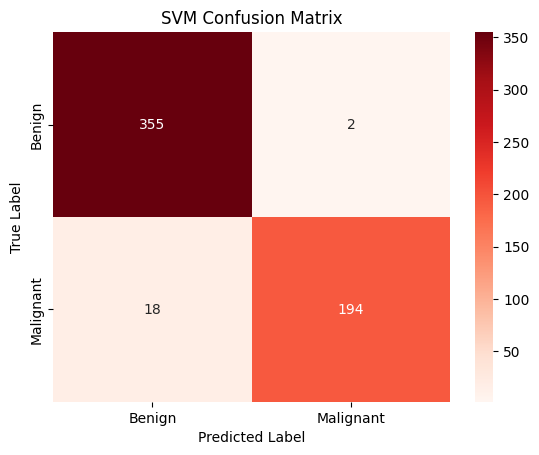

In [ ]:
#model performance
print(classification_report(y_true_svm,y_pred_svm, target_names=['Benign', 'Malignant']))

svm_cm = confusion_matrix(y_true_svm, y_pred_svm, labels=[0, 1])
sns.heatmap(svm_cm,annot=True,fmt='d',cmap='Reds', xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('SVM Confusion Matrix')

##K-NN

In [ ]:
y_true_knn = []
y_pred_knn = []

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for fold, (train_index, test_index) in enumerate(skf.split(X, y), 1):
    X_train, X_test = X.iloc[train_index], X.iloc[test_index]
    y_train, y_test = y.iloc[train_index], y.iloc[test_index]

    # Scale features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    #LDA
    lda = LDA(n_components=1)
    X_train_lda = lda.fit_transform(X_train_scaled, y_train)
    X_test_lda = lda.transform(X_test_scaled)

    # Grid Search
    knn = KNeighborsClassifier()
    params = {
        'n_neighbors': [3, 5, 7],
        'p': [1,2]
    }

    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    grid_search_knn = GridSearchCV(estimator=knn, param_grid=params, cv=cv, scoring='roc_auc')
    result = grid_search_knn.fit(X_train_lda, y_train)

    k = result.best_params_['n_neighbors']
    distance = result.best_params_['p']

    print("k = ", k, "distance metric = ", distance)

    knn = KNeighborsClassifier(n_neighbors = k, p = distance)
    knn.fit(X_train_lda, y_train)
    y_pred_fold = knn.predict(X_test_lda)

    y_true_knn.extend(y_test.tolist())
    y_pred_knn.extend(y_pred_fold.tolist())

k =  5 distance metric =  1
k =  7 distance metric =  1
k =  7 distance metric =  1
k =  7 distance metric =  1
k =  7 distance metric =  1


To be able to find the parameter K and the distance metric we used exhausted grid search.
* k is the number of nearest neighbors. It selects the closest k points and predicts based on their distance. Its value affects the variance and bias with a small k leading to overfitting and a large k to underfitting
* distance metric decides wether we will be using manhattan distance or eucledian to calculate the distance within samples

stratifiedkfold for validation
* We used k=5 for our k fold since this is a standard value
* decided to shuffle the samples to have a more reliable estimate

We used ROC_AUC since it compares the True Positive Rate with the False Positive rate choosing a curve that is accurate and can distinguish these two classification properly. This was chosen over accuracy since our data is skewed

In [ ]:
print(classification_report(y_true_knn,y_pred_knn, target_names=['Benign', 'Malignant']))

knn_cm = confusion_matrix(y_true_knn, y_pred_knn, labels=[0, 1])
sns.heatmap(svm_cm,annot=True,fmt='d',cmap='Blues', xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('K-NN Confusion Matrix')

NameError: name 'classification_report' is not defined

#Comparative analysis

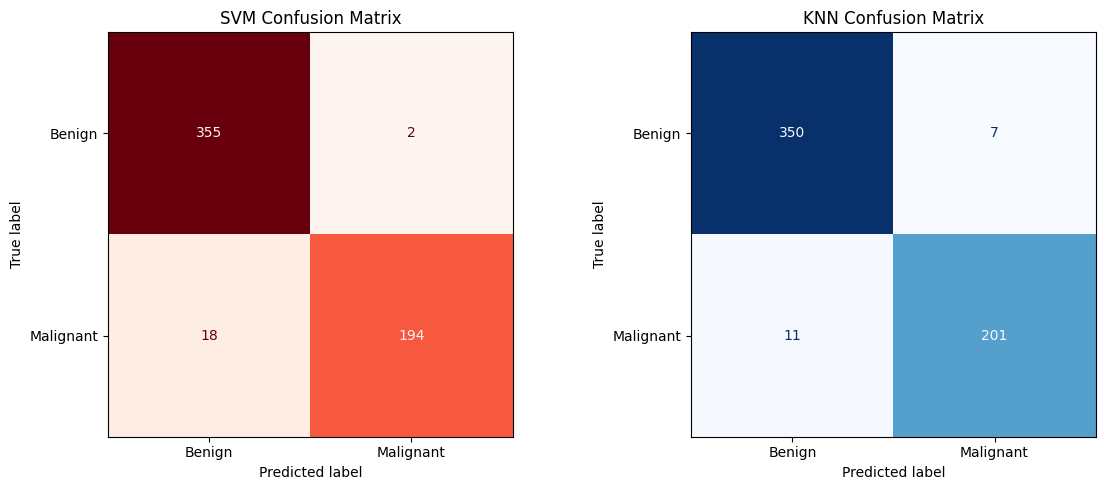

SVM:
              precision    recall  f1-score   support

      Benign       0.95      0.99      0.97       357
   Malignant       0.99      0.92      0.95       212

    accuracy                           0.96       569
   macro avg       0.97      0.95      0.96       569
weighted avg       0.97      0.96      0.96       569

K-NN:
              precision    recall  f1-score   support

      Benign       0.97      0.98      0.97       357
   Malignant       0.97      0.95      0.96       212

    accuracy                           0.97       569
   macro avg       0.97      0.96      0.97       569
weighted avg       0.97      0.97      0.97       569



In [ ]:

fig, axes = plt.subplots(1, 2, figsize=(12,5))

ConfusionMatrixDisplay(svm_cm, display_labels=['Benign', 'Malignant']).plot(ax=axes[0], cmap='Reds', colorbar=False)
axes[0].set_title('SVM Confusion Matrix')

ConfusionMatrixDisplay(knn_cm, display_labels=['Benign', 'Malignant']).plot(ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title('KNN Confusion Matrix')

plt.tight_layout()
plt.show()
print("SVM:")
print(classification_report(y_true_svm,y_pred_svm, target_names=['Benign', 'Malignant']))
print("K-NN:")
print(classification_report(y_true_knn,y_pred_knn, target_names=['Benign', 'Malignant']))

Both of these classification methods had really good performance scores. However, based on these values K-NN is the classification method I would feel more confident in using. This is because in scenarios such as cancer classification we would rather have a better true prositive rate/ recall than other metrics like precission. This is because patients given false negatives could not receive the care needed to treat their cancer. It also has a higher f1 score which is important to note since we had an imbalanced dataset

#Ethics

Although classification of tumors, can help a lot people identify if they have cancer the results showed that a large amount of malignant tumors were classified as benign. This could cause serious harm to patients that are given false negatives since this would indicate that they will be missin treatment that is necessary to save their lives specially when it comes to cancer since the rate of recession is higher when identified early. On the other hand if someone is given a false positive this could create unessesary stress for the patient. However, someone who is classified as having cancer will most likley go through other medical procedures to verify it compared to somone who is classified as having a benigne tumor. Sadly, human error does exist but our trust in machines and relianced has increased exponentially making it even more harmful if a test such as this one is solely relied on.

#Blibiography

B. Zhang, H. Shi, and H. Wang, “Machine Learning and AI in Cancer Prognosis, Prediction, and Treatment Selection: a Critical Approach,” Journal of Multidisciplinary Healthcare, vol. Volume 16, no. 16, pp. 1779–1791, Jun. 2023, doi: https://doi.org/10.2147/jmdh.s410301.

Batool, S., et al. (2024). A comparative performance assessment of artificial intelligence methods for medical diagnosis using feature reduction and classification. Information Sciences. https://doi.org/10.1016/j.ins.2024.02.046

Egwom, O. J., et al. (2022). An LDA–SVM machine learning model for breast cancer classification. BioMedInformatics, 2(3), 345–358. https://doi.org/10.3390/biomedinformatics2030022

Kumar, M., et al. (2022). Optimized stacking ensemble learning model for breast cancer detection and classification using machine learning. Sustainability, 14(21), 13998. https://doi.org/10.3390/su142113998
